# Baseline Recommendation Model

## TF-IDF + Mean Pooling + Cosine Similarity

Dataset: MIND-small

Objective:
Recommend relevant items based on users' historical
click behavior.

## 1. Environment and Configuration

In [1]:
import sys
import numpy as np
import pandas as pd
import sklearn

from pathlib import Path

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: 3.11.18
NumPy: 2.4.6
Pandas: 3.1.1
Scikit-learn: 1.9.1


In [2]:
# Dataset Paths

DATASET_DIR = Path("../../Dataset")

TRAIN_DIR = DATASET_DIR / "train"
VALIDATION_DIR = DATASET_DIR / "validation"

TRAIN_NEWS_PATH = TRAIN_DIR / "news.tsv"
TRAIN_BEHAVIORS_PATH = TRAIN_DIR / "behaviors.tsv"

VALIDATION_NEWS_PATH = VALIDATION_DIR / "news.tsv"
VALIDATION_BEHAVIORS_PATH = VALIDATION_DIR / "behaviors.tsv"

# Check Dataset Files
paths = [
    TRAIN_NEWS_PATH,
    TRAIN_BEHAVIORS_PATH,
    VALIDATION_NEWS_PATH,
    VALIDATION_BEHAVIORS_PATH
]

for path in paths:
    print("FOUND" if path.is_file() else "MISSING", path
)

assert all(path.is_file() for path in paths), \
    "Dataset files are missing."

FOUND ../../Dataset/train/news.tsv
FOUND ../../Dataset/train/behaviors.tsv
FOUND ../../Dataset/validation/news.tsv
FOUND ../../Dataset/validation/behaviors.tsv


## 2. Data Loading and Exploratory Data Analysis

- Load news metadata
- Load user behavior records
- Analyze dataset statistics
- Inspect user click history and impressions

In [3]:
NEWS_COLUMNS = [
    "news_id",
    "category",
    "subcategory",
    "title",
    "abstract",
    "url",
    "title_entities",
    "abstract_entities"
]

BEHAVIOR_COLUMNS = [
    "impression_id",
    "user_id",
    "time",
    "history",
    "impressions"
]

In [4]:
import csv

# Load news data
train_news = pd.read_csv(
    TRAIN_NEWS_PATH,
    sep="\t",             # 使用 Tab 分隔数据
    header=None,          # 原始文件没有表头
    names=NEWS_COLUMNS,   # 手动指定列名
    quoting=csv.QUOTE_NONE, # 不将引号解释为 CSV 引用符
    keep_default_na=False   # 保留空字符串，而不是自动转换为 NaN
)

validation_news = pd.read_csv(
    VALIDATION_NEWS_PATH,
    sep="\t",
    header=None,
    names=NEWS_COLUMNS,
    quoting=csv.QUOTE_NONE,
    keep_default_na=False
)

# Load user behavior data
train_behaviors = pd.read_csv(
    TRAIN_BEHAVIORS_PATH,
    sep="\t",
    header=None,
    names=BEHAVIOR_COLUMNS,
    quoting=csv.QUOTE_NONE,
    keep_default_na=False
)

validation_behaviors = pd.read_csv(
    VALIDATION_BEHAVIORS_PATH,
    sep="\t",
    header=None,
    names=BEHAVIOR_COLUMNS,
    quoting=csv.QUOTE_NONE,
    keep_default_na=False
)

In [5]:
print("=" * 40)
print("DATASET STATISTICS")
print("=" * 40)

print("Train News:", train_news.shape)
print("Train Behaviors:", train_behaviors.shape)

print("Validation News:", validation_news.shape)
print("Validation Behaviors:", validation_behaviors.shape)

print("-" * 40)

print("Train Users:", train_behaviors["user_id"].nunique())
print("Train News Categories:", train_news["category"].nunique())
print("Train News Subcategories:", train_news["subcategory"].nunique())


print("-" * 40)

display(train_news[["news_id", "category", "subcategory", "title", "abstract"]].head(10))
display(train_behaviors.head(10))

DATASET STATISTICS
Train News: (51282, 8)
Train Behaviors: (156965, 5)
Validation News: (42416, 8)
Validation Behaviors: (73152, 5)
----------------------------------------
Train Users: 50000
Train News Categories: 17
Train News Subcategories: 264
----------------------------------------


,news_id,category,subcategory,title,abstract
0,N55528,lifestyle,lifestyleroyals,"The Brands Queen Elizabeth, Prince Charles, an...","Shop the notebooks, jackets, and more that the..."
1,N19639,health,weightloss,50 Worst Habits For Belly Fat,These seemingly harmless habits are holding yo...
2,N61837,news,newsworld,The Cost of Trump's Aid Freeze in the Trenches...,Lt. Ivan Molchanets peeked over a parapet of s...
3,N53526,health,voices,I Was An NBA Wife. Here's How It Affected My M...,"I felt like I was a fraud, and being an NBA wi..."
4,N38324,health,medical,"How to Get Rid of Skin Tags, According to a De...","They seem harmless, but there's a very good re..."
5,N2073,sports,football_nfl,Should NFL be able to fine players for critici...,Several fines came down against NFL players fo...
6,N49186,weather,weathertopstories,It's been Orlando's hottest October ever so fa...,There won't be a chill down to your bones this...
7,N59295,news,newsworld,Chile: Three die in supermarket fire amid prot...,Three people have died in a supermarket fire a...
8,N24510,entertainment,gaming,Best PS5 games: top PlayStation 5 titles to lo...,Every confirmed or expected PS5 game we can't ...
9,N39237,news,newsscienceandtechnology,"How to report weather-related closings, delays","When there are active closings, view them here..."


,impression_id,user_id,time,history,impressions
0,1,U13740,11/11/2019 9:05:58 AM,N55189 N42782 N34694 N45794 N18445 N63302 N104...,N55689-1 N35729-0
1,2,U91836,11/12/2019 6:11:30 PM,N31739 N6072 N63045 N23979 N35656 N43353 N8129...,N20678-0 N39317-0 N58114-0 N20495-0 N42977-0 N...
2,3,U73700,11/14/2019 7:01:48 AM,N10732 N25792 N7563 N21087 N41087 N5445 N60384...,N50014-0 N23877-0 N35389-0 N49712-0 N16844-0 N...
3,4,U34670,11/11/2019 5:28:05 AM,N45729 N2203 N871 N53880 N41375 N43142 N33013 ...,N35729-0 N33632-0 N49685-1 N27581-0
4,5,U8125,11/12/2019 4:11:21 PM,N10078 N56514 N14904 N33740,N39985-0 N36050-0 N16096-0 N8400-1 N22407-0 N6...
5,6,U19739,11/11/2019 6:52:13 PM,N39074 N14343 N32607 N32320 N22007 N442 N19001...,N21119-1 N53696-0 N33619-1 N25722-0 N2869-0
6,7,U8355,11/11/2019 12:22:09 PM,N8419 N15771 N1431 N5888 N18663 N24123 N22130 ...,N51346-0 N33848-0 N15132-0 N10688-0 N6342-0 N6...
7,8,U46596,11/12/2019 10:29:36 PM,N47438 N20950 N21317 N5469,N7821-0 N24898-0 N12029-0 N13579-0 N42977-0 N3...
8,9,U79199,11/13/2019 10:13:02 AM,N37083 N459 N29499 N38118 N37378 N24691 N27235...,N51048-1 N64094-0 N13907-0 N39010-0
9,10,U53231,11/11/2019 11:28:11 AM,N58936 N15919 N11917 N2153 N55312 N13008 N4142...,N53585-1 N55689-0


In [6]:
# Select a user behavior with a non-empty history  解析一条用户行为记录
sample = train_behaviors[train_behaviors["history"].ne("")].iloc[0]
print("User ID:", sample["user_id"])
print("Time:", sample["time"])

# Parse click history
history_ids = sample["history"].split()

# Parse candidate impressions
impression_items = sample["impressions"].split()

print("\nHistory IDs:")
print(history_ids)

print("\nImpression Items:")
print(impression_items)

User ID: U13740
Time: 11/11/2019 9:05:58 AM

History IDs:
['N55189', 'N42782', 'N34694', 'N45794', 'N18445', 'N63302', 'N10414', 'N19347', 'N31801']

Impression Items:
['N55689-1', 'N35729-0']


In [7]:
# 将候选新闻 ID 和 Label 分开
candidate_ids = []
labels = []

for item in impression_items:
    news_id, label = item.rsplit("-", 1)        # item = "N104-1" → news_id = "N104"  label = "1"

    candidate_ids.append(news_id)
    labels.append(int(label))

print("Candidate IDs:", candidate_ids)
print("Labels:", labels)

Candidate IDs: ['N55689', 'N35729']
Labels: [1, 0]


In [8]:
# 将新闻 ID 转换成真实内容
# Display historical news
history_news = train_news[train_news["news_id"].isin(history_ids)]
display(history_news[["news_id", "category", "title"]])

print("-" * 40)

# 查看候选新闻的内容及对应 Label
candidate_df = pd.DataFrame({"news_id": candidate_ids, "label": labels})
candidate_df = candidate_df.merge(train_news[["news_id", "category", "title"]],
    on="news_id",
    how="left"
)

display(candidate_df)

,news_id,category,title
2077,N31801,news,Joe Biden reportedly denied Communion at a Sou...
4945,N63302,lifestyle,This Wedding Photo of a Canine Best Man Captur...
6892,N55189,tv,"'Wheel Of Fortune' Guest Delivers Hilarious, O..."
10049,N42782,sports,Three takeaways from Yankees' ALCS Game 5 vict...
13910,N19347,news,Former US Senator Kay Hagan dead at 66
14070,N10414,movies,"Robert Evans, 'Chinatown' Producer and Paramou..."
15555,N34694,tv,Rosie O'Donnell: Barbara Walters Isn't 'Up to ...
21466,N45794,news,Four flight attendants were arrested in Miami'...
26357,N18445,sports,Michigan sends breakup tweet to Notre Dame as ...


----------------------------------------


,news_id,label,category,title
0,N55689,1,sports,"Charles Rogers, former Michigan State football..."
1,N35729,0,news,Porsche launches into second story of New Jers...


In [9]:
# 检查数据缺失情况

print("=" * 50)
print("DATA QUALITY CHECK")
print("=" * 50)

print("\nEmpty News Fields:")
print(train_news.eq("").sum())

print("\nEmpty Behavior Fields:")
print(train_behaviors.eq("").sum())

print("\nDuplicate News IDs:")
print(train_news["news_id"].duplicated().sum())

print("\nEmpty User History:")
print(train_behaviors["history"].eq("").sum())

print("\nEmpty Impressions:")
print(train_behaviors["impressions"].eq("").sum())

DATA QUALITY CHECK

Empty News Fields:
news_id                 0
category                0
subcategory             0
title                   0
abstract             2666
url                     0
title_entities          0
abstract_entities       0
dtype: int64

Empty Behavior Fields:
impression_id       0
user_id             0
time                0
history          3238
impressions         0
dtype: int64

Duplicate News IDs:
0

Empty User History:
3238

Empty Impressions:
0


History Length Statistics:
count    156965.000000
mean         32.539987
std          40.267607
min           0.000000
25%           8.000000
50%          19.000000
75%          42.000000
max         558.000000
Name: history, dtype: float64


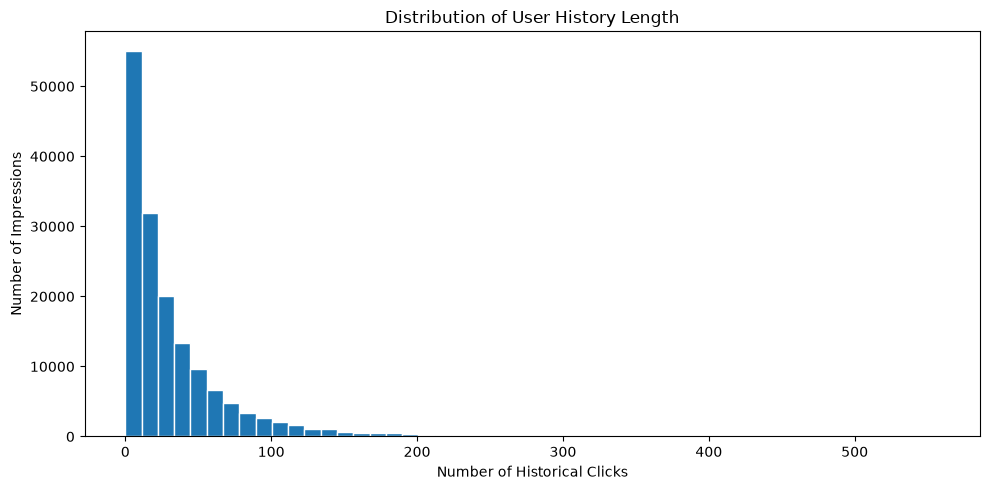

In [10]:
# 查看用户历史浏览数量分布
history_lengths = (
    train_behaviors["history"]
    .str.split()
    .str.len()
)
print("History Length Statistics:")
print(history_lengths.describe())


import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.hist(
    history_lengths,
    bins=50,
    edgecolor="White"
)
plt.title("Distribution of User History Length")
plt.xlabel("Number of Historical Clicks")
plt.ylabel("Number of Impressions")
plt.tight_layout()
plt.show()

## 3. Data Preprocessing

- Construct item text features
- Parse user click history
- Parse candidate items and labels
- Split training and validation datasets
- Check data integrity

In [11]:
# Configuration

MAX_HISTORY_LENGTH = 50     # 最多保留50条历史点击
TRAIN_RATIO = 0.8           # 原始训练集中约80%用于训练
RANDOM_SEED = 42

In [12]:
def prepare_news(news_df):
    news_df = news_df.copy()

    text_columns = [
        "category",
        "subcategory",
        "title",
        "abstract"
    ]

    # Clean text fields
    for column in text_columns:
        news_df[column] = (
            news_df[column]
            .fillna("")
            .astype(str)
            .str.strip()
        )

    # Combine text features
    news_df["content"] = (
        news_df["category"] + "  " +
        news_df["subcategory"] + "  " +
        news_df["title"] + "  " +
        news_df["abstract"]
    ).str.strip()

    return news_df


train_news = prepare_news(train_news)
display(train_news[["news_id", "content"]].head())

,news_id,content
0,N55528,lifestyle lifestyleroyals The Brands Queen E...
1,N19639,health weightloss 50 Worst Habits For Belly ...
2,N61837,news newsworld The Cost of Trump's Aid Freez...
3,N53526,health voices I Was An NBA Wife. Here's How ...
4,N38324,"health medical How to Get Rid of Skin Tags, ..."


In [13]:
# 解析用户历史记录
def parse_history(history):
    history_ids = history.split()

    return history_ids[-MAX_HISTORY_LENGTH:]


def parse_impressions(impressions):
    candidate_ids = []
    labels = []

    for item in impressions.split():
        news_id, label = item.rsplit("-", 1)  
        # "N101-1 N102-0 N103-1"
            # Candidate IDs: ['N101', 'N102', 'N103']
            # Labels: [1, 0, 1]
        candidate_ids.append(news_id)
        labels.append(int(label))

    return candidate_ids, labels

# 只是做测试
test_impressions = "N101-1 N102-0 N103-1"
candidate_ids, labels = parse_impressions(test_impressions)

print("Candidate IDs:", candidate_ids)
print("Labels:", labels)

Candidate IDs: ['N101', 'N102', 'N103']
Labels: [1, 0, 1]


In [14]:
# 预处理全部用户行为
def prepare_behaviors(behaviors_df):
    behaviors_df = behaviors_df.copy()

    # Convert time string to datetime
    behaviors_df["time"] = pd.to_datetime(
        behaviors_df["time"],
        format="%m/%d/%Y %I:%M:%S %p"
    )

    # Parse historical clicks
    behaviors_df["history_ids"] = (behaviors_df["history"].apply(parse_history))

    # Parse candidate items and labels
    parsed = behaviors_df["impressions"].apply(parse_impressions)

    behaviors_df["candidate_ids"] = parsed.apply(lambda x: x[0])
    behaviors_df["labels"] = parsed.apply(lambda x: x[1])

    return behaviors_df


train_behaviors = prepare_behaviors(train_behaviors)
display(
    train_behaviors[
        [
            "user_id",
            "time",
            "history_ids",
            "candidate_ids",
            "labels"
        ]
    ].head()
)

,user_id,time,history_ids,candidate_ids,labels
0,U13740,2019-11-11 09:05:58,"[N55189, N42782, N34694, N45794, N18445, N6330...","[N55689, N35729]","[1, 0]"
1,U91836,2019-11-12 18:11:30,"[N19709, N31402, N31741, N54889, N9798, N62612...","[N20678, N39317, N58114, N20495, N42977, N2240...","[0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0]"
2,U73700,2019-11-14 07:01:48,"[N10732, N25792, N7563, N21087, N41087, N5445,...","[N50014, N23877, N35389, N49712, N16844, N5968...","[0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ..."
3,U34670,2019-11-11 05:28:05,"[N45729, N2203, N871, N53880, N41375, N43142, ...","[N35729, N33632, N49685, N27581]","[0, 0, 1, 0]"
4,U8125,2019-11-12 16:11:21,"[N10078, N56514, N14904, N33740]","[N39985, N36050, N16096, N8400, N22407, N60408...","[0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."


# 划分 Training、Validation、Test

按照时间划分数据集

In [15]:
# Sort behaviors by time
sorted_behaviors = train_behaviors.sort_values(by="time").reset_index(drop=True)

# Determine split time
split_index = int(len(sorted_behaviors) * TRAIN_RATIO)    # TRAIN_RATIO = 0.8 原始训练集中约80%用于训练
split_time = sorted_behaviors.iloc[split_index]["time"]

# Split training and validation data
train_df = sorted_behaviors[sorted_behaviors["time"] < split_time].copy().reset_index(drop=True)
validation_df = sorted_behaviors[sorted_behaviors["time"] >= split_time].copy().reset_index(drop=True)

print("Training Samples:", len(train_df))
print("Validation Samples:", len(validation_df))

print("\nTraining Time Range:")
print(train_df["time"].min())
print(train_df["time"].max())

print("Validation Time Range:")
print(validation_df["time"].min())
print(validation_df["time"].max())

Training Samples: 125572
Validation Samples: 31393

Training Time Range:
2019-11-09 00:00:19
2019-11-13 20:36:19
Validation Time Range:
2019-11-13 20:36:26
2019-11-14 23:59:13


In [16]:
train_item_ids = set()

# Collect historical news IDs
for ids in train_df["history_ids"]:
    train_item_ids.update(ids)

# Collect candidate news IDs
for ids in train_df["candidate_ids"]:
    train_item_ids.update(ids)

# Select news used for TF-IDF fitting
fit_news = train_news[train_news["news_id"].isin(train_item_ids)].copy()

print("Original News:", len(train_news))
print("TF-IDF Fit News:", len(fit_news))
print("Unique Training Item IDs:", len(train_item_ids))


Original News: 51282
TF-IDF Fit News: 45243
Unique Training Item IDs: 45243


In [17]:
print("=" * 50)
print("PREPROCESSING QUALITY CHECK")
print("=" * 50)

# Maximum history length
max_history = (train_behaviors["history_ids"].apply(len).max())
print("Maximum History Length:", max_history)

# Check candidate-label alignment
alignment_valid = (train_behaviors["candidate_ids"].apply(len) == train_behaviors["labels"].apply(len)).all()
print("Candidate-Label Alignment:", alignment_valid)

# Check label values
unique_labels = set(train_behaviors["labels"].explode().unique())
print("Unique Labels:", unique_labels)

# Check temporal split
time_order_valid = (train_df["time"].max() < validation_df["time"].min())
print("Temporal Split Valid:", time_order_valid)

# Check empty content
print("Empty News Content:", train_news["content"].eq("").sum())

assert max_history <= MAX_HISTORY_LENGTH
assert alignment_valid
assert unique_labels == {0, 1}
assert time_order_valid
assert len(train_df) + len(validation_df) == len(train_behaviors)

PREPROCESSING QUALITY CHECK
Maximum History Length: 50
Candidate-Label Alignment: True
Unique Labels: {0, 1}
Temporal Split Valid: True
Empty News Content: 0


In [18]:
available_news_ids = set(train_news["news_id"])

history_news_ids = set()
candidate_news_ids = set()

for ids in train_behaviors["history_ids"]:
    history_news_ids.update(ids)

for ids in train_behaviors["candidate_ids"]:
    candidate_news_ids.update(ids)

missing_history_ids = (history_news_ids - available_news_ids)
missing_candidate_ids = (candidate_news_ids - available_news_ids)

print("Unique History News:", len(history_news_ids))
print("Unique Candidate News:", len(candidate_news_ids))

print("Missing History News:", len(missing_history_ids))
print("Missing Candidate News:", len(missing_candidate_ids))

Unique History News: 31091
Unique Candidate News: 20288
Missing History News: 0
Missing Candidate News: 0


## 4. TF-IDF Vectorization

- Initialize TF-IDF Vectorizer
- Fit vocabulary and IDF on training corpus
- Transform news content into sparse vectors
- Construct news ID to matrix index mapping
- Inspect learned text features

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

# 初始化 TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_features=30000,
    norm="l2",
    dtype=np.float32
)

# 拟合 TF-IDF
# Fit TF-IDF on training corpus only
tfidf.fit(fit_news["content"])

print("Training Corpus Size:", len(fit_news))
print("Vocabulary Size:", len(tfidf.vocabulary_))
print("IDF Shape:", tfidf.idf_.shape)

Training Corpus Size: 45243
Vocabulary Size: 30000
IDF Shape: (30000,)


In [20]:
# Transform news content into TF-IDF vectors

news_matrix = tfidf.transform(train_news["content"])

print("News Matrix Shape:", news_matrix.shape)
print("Matrix Type:", type(news_matrix))
print("Matrix Data Type:", news_matrix.dtype)

News Matrix Shape: (51282, 30000)
Matrix Type: <class 'scipy.sparse._csr.csr_matrix'>
Matrix Data Type: float32


In [21]:
# 检查稀疏矩阵大小
rows, columns = news_matrix.shape

total_elements = rows * columns

non_zero_elements = news_matrix.nnz

density = non_zero_elements / total_elements

sparsity = 1 - density

print("Total Elements:", total_elements)

print("Non-zero Elements:", non_zero_elements)

print("Density:", f"{density:.4%}")

print("Sparsity:", f"{sparsity:.4%}")

Total Elements: 1538460000
Non-zero Elements: 1464217
Density: 0.0952%
Sparsity: 99.9048%


In [22]:
dense_bytes = (
    total_elements * news_matrix.dtype.itemsize
)

sparse_bytes = (
    news_matrix.data.nbytes
    + news_matrix.indices.nbytes
    + news_matrix.indptr.nbytes
)

print(
    "Dense Matrix Memory (MB):",
    round(dense_bytes / 1024**2, 2)
)

print(
    "Sparse Matrix Memory (MB):",
    round(sparse_bytes / 1024**2, 2)
)

print(
    "Memory Reduction:",
    f"{1 - sparse_bytes / dense_bytes:.2%}"
)

Dense Matrix Memory (MB): 5868.76
Sparse Matrix Memory (MB): 11.37
Memory Reduction: 99.81%


In [23]:
news_id_to_index = {
    news_id: index
    for index, news_id in enumerate(
        train_news["news_id"]
    )
}

print("Mapping Size:", len(news_id_to_index))

print(
    "Mapping Examples:",
    list(news_id_to_index.items())[:5]
)

Mapping Size: 51282
Mapping Examples: [('N55528', 0), ('N19639', 1), ('N61837', 2), ('N53526', 3), ('N38324', 4)]


In [24]:
feature_names = tfidf.get_feature_names_out()

print("Number of Features:", len(feature_names))

print("First 20 Features:")

print(feature_names[:20])

Number of Features: 30000
First 20 Features:
['00' '00 pm' '000' '000 000' '000 acre' '000 acres' '000 bond' '000 cash'
 '000 curious' '000 customers' '000 feet' '000 fine' '000 homes'
 '000 miles' '000 new' '000 people' '000 pounds' '000 power'
 '000 residents' '000 reward']


In [25]:
def get_top_tfidf_features(news_id, top_k=10):

    index = news_id_to_index[news_id]

    vector = news_matrix[index]

    # Get non-zero feature indices
    feature_indices = vector.indices

    # Get corresponding TF-IDF weights
    feature_weights = vector.data

    # Sort weights in descending order
    sorted_indices = np.argsort(
        feature_weights
    )[::-1][:top_k]

    return pd.DataFrame({
        "feature": feature_names[
            feature_indices[sorted_indices]
        ],
        "tfidf_weight": feature_weights[
            sorted_indices
        ]
    })